In [1]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
from typing import List, Optional, NamedTuple, Union
from jaxtyping import Array, Float, Int

# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive, PosteriorGaussianSumFiltered, _process_input, _get_params, swap_axes_on_values
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF


import matplotlib.pyplot as plt
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [2]:
# Parameters
state_dim = 1
state_noise_dim = 1
emission_dim = 1
emission_noise_dim = 1
seq_length = 100
mu0 = 0.0 * jnp.zeros(state_dim)
q0 = jnp.zeros(state_noise_dim)
r0 = jnp.zeros(emission_noise_dim)
Sigma0 = 1.0 * jnp.eye(state_dim)
Q = 1.0 * jnp.eye(state_noise_dim)
R = 1.0 * jnp.eye(emission_noise_dim)

# ICASSP
# f1 = lambda x, q, u: (1-u) * x / 2.  + u * jnp.sin(10 * x) + q
f1 = lambda x, q, u: 20 * jnp.sin(10 * x) + q
g1 = lambda x, r, u:  0.01 * jnp.dot(x, x) + r
def g1lp(x,y,u):
    return MVN(loc = g1(x, r0, u), covariance_matrix = R).log_prob(y)


# Lorenz 63
def lorentz_63(x, sigma=10, rho=28, beta=2.667, dt=0.01):
    dx = dt * sigma * (x[1] - x[0])
    dy = dt * (x[0] * rho - x[1] - x[0] *x[2]) 
    dz = dt * (x[0] * x[1] - beta * x[2])
    return jnp.array([dx+x[0], dy+x[1], dz+x[2]])
f63 = lambda x, q, u: lorentz_63(x) + q

# stochastic growth model
f3 = lambda x, q, u: x / 2. + 25. * x / (1 + jnp.power(x, 2)) + q
g3 = lambda x, r, u: u * 0.8 * x + (1-u) * jnp.dot(x, x) + r 
def g3lp(x,y,u):
    return MVN(loc = g3(x, 0.0, u), covariance_matrix = R).log_prob(y)


# Stochastic Volatility
alpha = 0.91
sigma = 1.0
beta = 0.5
fsv= lambda x, q, u: alpha * x + sigma * q
gsv = lambda x, r, u: beta * jnp.exp(x/2) * r
def svlp(x,y,u):
    return MVN(loc = gsv(x, r0, u), covariance_matrix = gsv(x, 1.0, u)**2 * R).log_prob(y)

# Linear - Stochastic Volatility
alpha = 0.91
sigma = 5.0
beta = 0.5
glsv = lambda x, r, u: u * beta * jnp.exp(x/2) * r + (1-u) * (0.8 * x + r)
def lsvlp(x,y,u):
    return MVN(loc = glsv(x, r0, u), covariance_matrix = u * beta ** 2 * jnp.exp(x) * R + (1-u) * R).log_prob(y)

# Multivariate SV
Phi = 0.8 * jnp.eye(state_dim)
fmsv = lambda x, q, u: Phi @ x + q #((1-u) + 0.3*u)*q
gmsv = lambda x, r, u:  u * 0.5 * jnp.multiply(jnp.exp(x/2), r)
def msvlp(x,y,u):
    return MVN(loc = gmsv(x, r0, u), covariance_matrix = jnp.diag(jnp.exp(x/2.0)) @ R @ jnp.diag(jnp.exp(x/2.0))).log_prob(y)

# Linear - Multivariate SV
sigma = 5.0
beta = 0.5

H = 0.1 * jnp.eye(emission_dim, state_dim)
glmsv = lambda x, r, u: H @ x + r
# lambda x, r, u: 0 * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-0) * (H @ x + r)
def lmsvlp(x,y,u):
    # M = 0 * beta * jnp.diag(jnp.exp(x / sigma)) + (1-0) * jnp.eye(emission_dim)
    M = jnp.eye(emission_dim)
    return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)


# Linear-Gaussian SSM
A = 0.8 * jnp.eye(state_dim)
H = 0.1 * jnp.eye(emission_dim, state_dim)
fLG = lambda x, q, u: A @ x + q
gLG = lambda x, r, u: H @ x + r
gLGlp = lambda x,y,u: MVN(loc = gLG(x, 0.0, u), covariance_matrix = R).log_prob(y)

# Inputs
# inputs = 8. * jnp.cos(1.2 * jnp.arange(seq_length))
# sm = lambda x : jnp.exp(x) / (1+jnp.exp(x))
# inputs = sm(jnp.arange(seq_length)-50) # off - on gradually
# inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
# inputs = 1.0 * jnp.zeros(seq_length) # off
# inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
inputs = 1.0 * jnp.ones(seq_length) # on

f = f3
g = g3
glp = g3lp


In [3]:
params_bpf = ParamsBPF(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias=q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias=r0,
    emission_noise_covariance=R,
    emission_distribution_log_prob = glp
)

In [4]:
# initialization
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

sim 1/10
key0:  [2467461003  428148500]
key:  [3186719485 3840466878]
       Time taken for GSF:  0.40364789962768555
       Time taken for UGSF:  0.4230642318725586
       Time taken for AGSF:  0.9704210758209229
       Time taken for UAGSF:  1.2141940593719482
       Time taken for BPF:  0.6487720012664795
       Time taken for GSPF:  1.0822501182556152
              GSF RMSE: 1.084753
              UGSF RMSE: 1.0948427
              AGSF RMSE: 1.1654439
              UAGSF RMSE: 1.1490958
              BPF RMSE: 1.1820142
              GSPF RMSE: 1.1126337


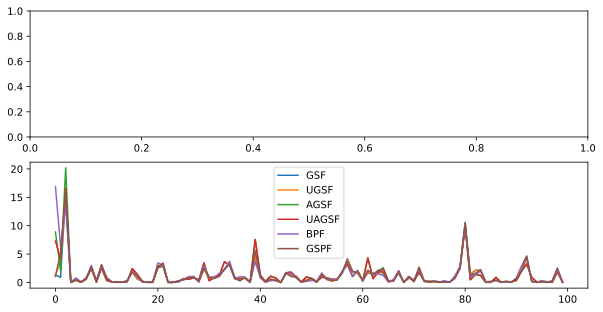

sim 2/10
key0:  [4038682467 4049047219]
key:  [1123993949 1633776119]
       Time taken for GSF:  0.1740891933441162
       Time taken for UGSF:  0.4123880863189697
       Time taken for AGSF:  0.8151891231536865
       Time taken for UAGSF:  1.1850440502166748
       Time taken for BPF:  0.3709602355957031
       Time taken for GSPF:  0.7074458599090576
              GSF RMSE: 1.1594425
              UGSF RMSE: 1.1612833
              AGSF RMSE: 1.2194338
              UAGSF RMSE: 1.2291983
              BPF RMSE: 1.1447438
              GSPF RMSE: 1.1703302


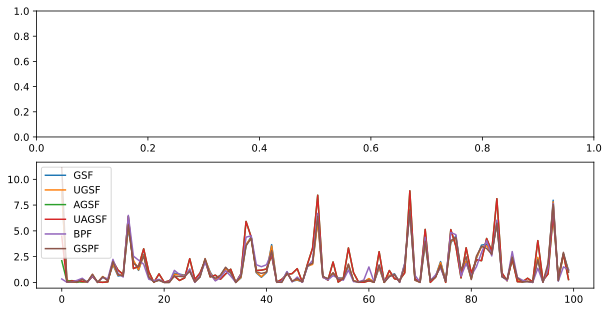

sim 3/10
key0:  [3295730785 1907469606]
key:  [2175656443 3507338041]
       Time taken for GSF:  0.15425801277160645
       Time taken for UGSF:  0.3975188732147217
       Time taken for AGSF:  0.9311428070068359
       Time taken for UAGSF:  1.1395108699798584
       Time taken for BPF:  0.36038708686828613
       Time taken for GSPF:  0.7024867534637451
              GSF RMSE: 1.2356623
              UGSF RMSE: 1.2318918
              AGSF RMSE: 1.3255994
              UAGSF RMSE: 1.3377717
              BPF RMSE: 1.3001852
              GSPF RMSE: 1.2423357


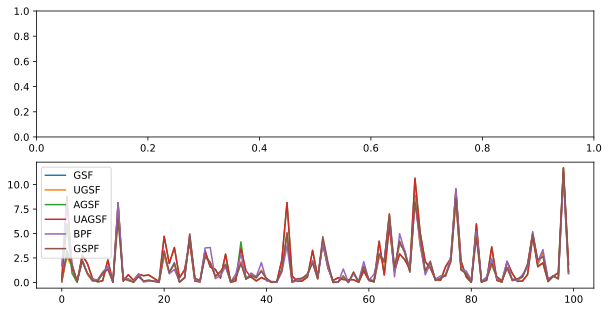

sim 4/10
key0:  [1795368326  584935165]
key:  [1120832370 3770592918]
       Time taken for GSF:  0.18623113632202148
       Time taken for UGSF:  0.41913390159606934
       Time taken for AGSF:  0.8448619842529297
       Time taken for UAGSF:  1.2171621322631836
       Time taken for BPF:  0.3764669895172119
       Time taken for GSPF:  0.8239002227783203
              GSF RMSE: 1.1218834
              UGSF RMSE: 1.1240408
              AGSF RMSE: 1.2454708
              UAGSF RMSE: 1.2448881
              BPF RMSE: 1.1435884
              GSPF RMSE: 1.1312248


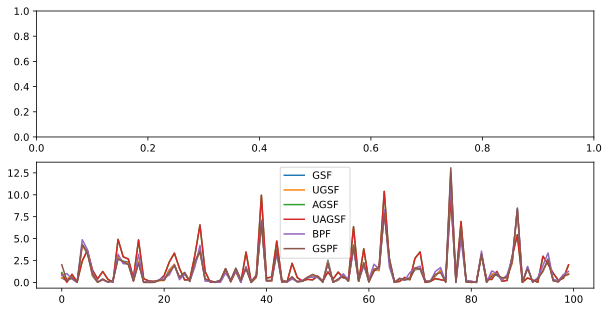

sim 5/10
key0:  [ 456292018 1165566599]
key:  [4102745572 3277364256]
       Time taken for GSF:  0.16475510597229004
       Time taken for UGSF:  0.3993809223175049
       Time taken for AGSF:  0.8746161460876465
       Time taken for UAGSF:  1.223417043685913
       Time taken for BPF:  0.376986026763916
       Time taken for GSPF:  0.7288999557495117
              GSF RMSE: 1.1060325
              UGSF RMSE: 1.1035728
              AGSF RMSE: 1.1345487
              UAGSF RMSE: 1.1409634
              BPF RMSE: 1.1513139
              GSPF RMSE: 1.1220546


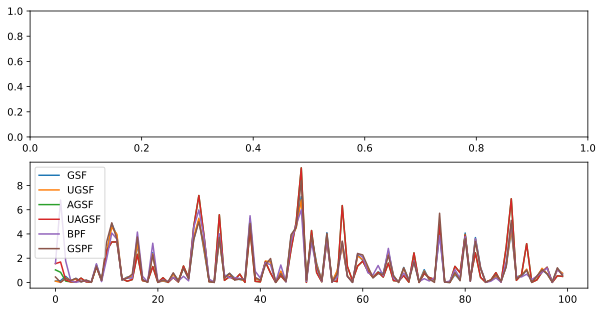

sim 6/10
key0:  [212254551 972031800]
key:  [4176427977  237722671]
       Time taken for GSF:  0.16515707969665527
       Time taken for UGSF:  0.4051849842071533
       Time taken for AGSF:  0.9085037708282471
       Time taken for UAGSF:  1.1980459690093994
       Time taken for BPF:  0.3702809810638428
       Time taken for GSPF:  0.7266800403594971
              GSF RMSE: 1.0928693
              UGSF RMSE: 1.0960274
              AGSF RMSE: 1.2561265
              UAGSF RMSE: 1.2615964
              BPF RMSE: 1.1654785
              GSPF RMSE: 1.1077187


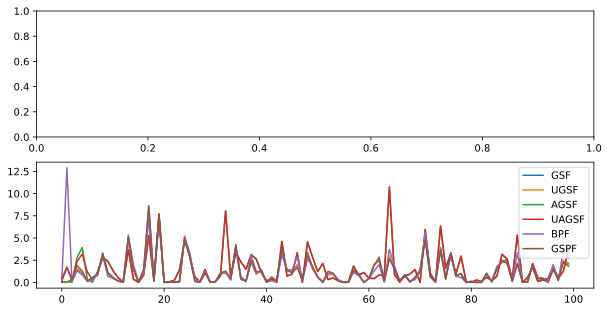

sim 7/10
key0:  [3685475569 1761638195]
key:  [1802191850  425137017]
       Time taken for GSF:  0.1609337329864502
       Time taken for UGSF:  0.3988978862762451
       Time taken for AGSF:  0.8567941188812256
       Time taken for UAGSF:  1.2029821872711182
       Time taken for BPF:  0.38013696670532227
       Time taken for GSPF:  0.7483339309692383
              GSF RMSE: 1.0017627
              UGSF RMSE: 1.007859
              AGSF RMSE: 1.0985007
              UAGSF RMSE: 1.1068676
              BPF RMSE: 1.0346551
              GSPF RMSE: 1.0298089


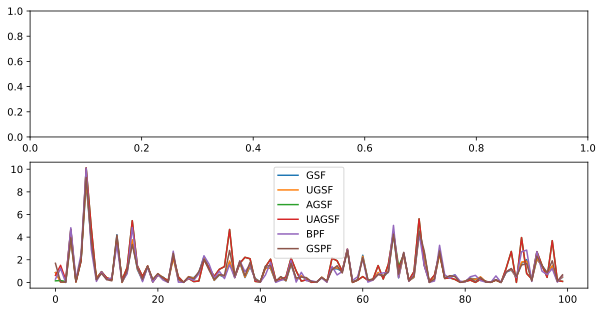

sim 8/10
key0:  [2004312237 1080707979]
key:  [3564672657 2387443400]
       Time taken for GSF:  0.1599738597869873
       Time taken for UGSF:  0.4751460552215576
       Time taken for AGSF:  0.8684420585632324
       Time taken for UAGSF:  1.1865580081939697
       Time taken for BPF:  0.3763899803161621
       Time taken for GSPF:  0.7402198314666748
              GSF RMSE: 0.9727365
              UGSF RMSE: 0.9727396
              AGSF RMSE: 1.0391195
              UAGSF RMSE: 1.0352958
              BPF RMSE: 1.0313371
              GSPF RMSE: 0.9703415


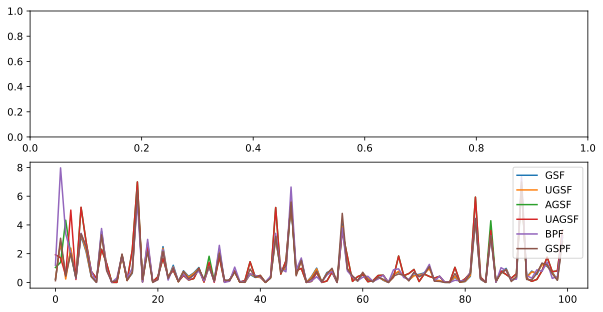

sim 9/10
key0:  [2372184986  857659058]
key:  [2470550142  587965772]
       Time taken for GSF:  0.16355204582214355
       Time taken for UGSF:  0.43068528175354004
       Time taken for AGSF:  0.8472540378570557
       Time taken for UAGSF:  1.2879879474639893
       Time taken for BPF:  0.3867969512939453
       Time taken for GSPF:  0.749567985534668
              GSF RMSE: 1.2674435
              UGSF RMSE: 1.2607253
              AGSF RMSE: 1.3085775
              UAGSF RMSE: 1.2887771
              BPF RMSE: 1.2307489
              GSPF RMSE: 7.1086392


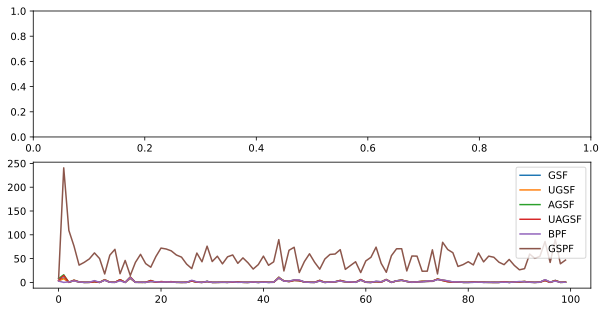

sim 10/10
key0:  [1353098956 1641448171]
key:  [ 605080484 2204356190]
       Time taken for GSF:  0.25817203521728516
       Time taken for UGSF:  0.3919680118560791
       Time taken for AGSF:  0.8772637844085693
       Time taken for UAGSF:  1.1910161972045898
       Time taken for BPF:  0.39795494079589844
       Time taken for GSPF:  0.7524020671844482
              GSF RMSE: 1.0424652
              UGSF RMSE: 1.0392412
              AGSF RMSE: 1.0845897
              UAGSF RMSE: 1.0913117
              BPF RMSE: 1.0308831
              GSPF RMSE: 1.06339


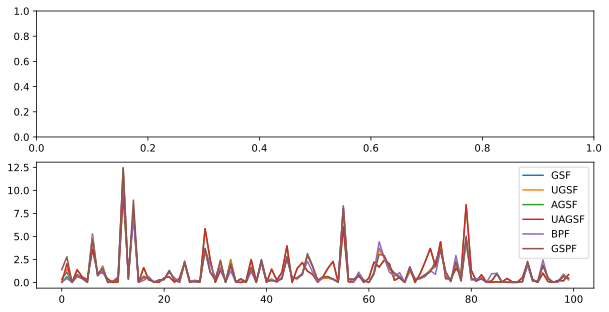

In [5]:
verbose = False
Nsim = 10
gsf_rmse = jnp.zeros(Nsim)
ugsf_rmse = jnp.zeros(Nsim)
agsf_rmse = jnp.zeros(Nsim)
uagsf_rmse = jnp.zeros(Nsim)
bpf_rmse = jnp.zeros(Nsim)
gspf_rmse = jnp.zeros(Nsim)

gsf_norm = jnp.zeros((Nsim, seq_length))
ugsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length))
uagsf_norm = jnp.zeros((Nsim, seq_length))
bpf_norm = jnp.zeros((Nsim, seq_length))
gspf_norm = jnp.zeros((Nsim, seq_length))

gsf_time = jnp.zeros(Nsim)
ugsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)
uagsf_time = jnp.zeros(Nsim)
bpf_time = jnp.zeros(Nsim)
gspf_time = jnp.zeros(Nsim)
next_key = jr.PRNGKey(0)
for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

    # GSF
    M = 10
    tin = time.time()
    posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, M, 1, inputs)
    point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
    tout = time.time()
    t_gsf= tout - tin
    print('       Time taken for GSF: ', tout - tin)

    # U-GSF
    tin = time.time()
    uparams = ParamsUKF(1,0,0)
    posterior_filtered_ugsf = gf.unscented_gaussian_sum_filter(params, uparams, emissions, M, 1, inputs)
    point_estimate_ugsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_ugsf.means, posterior_filtered_ugsf.weights), axis=0)
    tout = time.time()
    t_ugsf= tout - tin
    print('       Time taken for UGSF: ', tout - tin)

    # AGSF
    opt_args = (0.1, 0.1)
    num_components = [10, 2, 2]
    tin = time.time()
    posterior_filtered_agsf, aux_outputs = gf.speedy_augmented_gaussian_sum_filter(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)    
    point_estimate_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_agsf.means, posterior_filtered_agsf.weights), axis=0)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # U-AGSF
    tin = time.time()
    # posterior_filtered_uagsf, aux_outputs = gf.unscented_agsf(params, uparams, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)
    posterior_filtered_uagsf, aux_outputs = gf.speedy_unscented_agsf(params, uparams, emissions, num_components, key, opt_args, inputs=inputs)
    point_estimate_uagsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_uagsf.means, posterior_filtered_uagsf.weights), axis=0)
    tout = time.time()
    t_uagsf= tout - tin
    print('       Time taken for UAGSF: ', tout - tin)

    # BPF
    tin = time.time()
    num_particles = 100

    params_bpf = ParamsBPF(
        initial_mean=mu0,
        initial_covariance=Sigma0,
        dynamics_function=f,
        dynamics_noise_bias=q0,
        dynamics_noise_covariance=Q,
        emission_function=g,
        emission_noise_bias=r0,
        emission_noise_covariance=R,
        emission_distribution_log_prob = glp
    )

    posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs, 1.0)
    point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    tout = time.time()
    t_bpf = tout - tin
    print('       Time taken for BPF: ', tout - tin)

    # GS-PF
    tin = time.time()
    num_particles = 100
    num_components = 5
    posterior_gspf = gf.gaussian_sum_particle_filter(params_bpf, emissions, num_components, nprt = num_particles, key = key, inputs = inputs)
    point_estimate_gspf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_gspf.means, posterior_gspf.weights), axis=0)
    tout = time.time()
    t_gspf = tout - tin
    print('       Time taken for GSPF: ', tout - tin)

    # Computation of errors
    gsf_rmse = gsf_rmse.at[i].set(utils.rmse(point_estimate_gsf[:, (0,2)], states[:, (0,2)]))
    ugsf_rmse = ugsf_rmse.at[i].set(utils.rmse(point_estimate_ugsf[:, (0,2)], states[:, (0,2)]))
    agsf_rmse = agsf_rmse.at[i].set(utils.rmse(point_estimate_agsf[:, (0,2)], states[:, (0,2)]))
    uagsf_rmse = uagsf_rmse.at[i].set(utils.rmse(point_estimate_uagsf[:, (0,2)], states[:, (0,2)]))
    bpf_rmse = bpf_rmse.at[i].set(utils.rmse(point_estimate_bpf[:, (0,2)], states[:, (0,2)]))
    gspf_rmse = gspf_rmse.at[i].set(utils.rmse(point_estimate_gspf[:, (0,2)], states[:, (0,2)]))


    print('              GSF RMSE:', gsf_rmse[i])                                                                           
    print('              UGSF RMSE:', ugsf_rmse[i])
    print('              AGSF RMSE:', agsf_rmse[i])
    print('              UAGSF RMSE:', uagsf_rmse[i])
    print('              BPF RMSE:', bpf_rmse[i])
    print('              GSPF RMSE:', gspf_rmse[i])

    gsf_norm = gsf_norm.at[i].set(jnp.linalg.norm(point_estimate_gsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    ugsf_norm = ugsf_norm.at[i].set(jnp.linalg.norm(point_estimate_ugsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    agsf_norm = agsf_norm.at[i].set(jnp.linalg.norm(point_estimate_agsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    uagsf_norm = uagsf_norm.at[i].set(jnp.linalg.norm(point_estimate_uagsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    bpf_norm = bpf_norm.at[i].set(jnp.linalg.norm(point_estimate_bpf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    gspf_norm = gspf_norm.at[i].set(jnp.linalg.norm(point_estimate_gspf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)

    fig, axes = plt.subplots(2, 1, figsize=(10, 5))
    # axes[0].plot(states[:,0], label='True')
    # axes[0].plot(point_estimate_gsf[:,0], label='GSF')
    # axes[0].plot(point_estimate_ugsf[:,0], label='UGSF')
    # axes[0].plot(point_estimate_agsf[:,0], label='AGSF')
    # axes[0].plot(point_estimate_uagsf[:,0], label='UAGSF')
    # axes[0].plot(point_estimate_bpf[:,0], label='BPF')
    # axes[0].plot(emissions[:,0], label='Observed')
    # axes[0].legend()

    axes[1].plot(jnp.linalg.norm(point_estimate_gsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_ugsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_agsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_uagsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_bpf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_gspf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].legend(['GSF', 'UGSF', 'AGSF', 'UAGSF', 'BPF', 'GSPF'])

    plt.show()


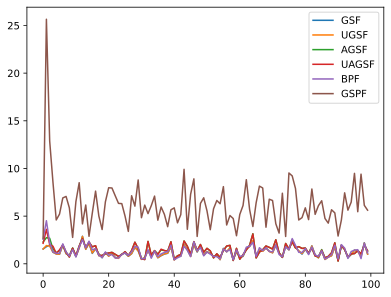

In [6]:
gsf_avg_norm = gsf_norm.sum(axis=0)/Nsim
ugsf_avg_norm = ugsf_norm.sum(axis=0)/Nsim
agsf_avg_norm = agsf_norm.sum(axis=0)/Nsim
uagsf_avg_norm = uagsf_norm.sum(axis=0)/Nsim
bpf_avg_norm = bpf_norm.sum(axis=0)/Nsim
gspf_avg_norm = gspf_norm.sum(axis=0)/Nsim


plt.plot(gsf_avg_norm, label='GSF')
plt.plot(ugsf_avg_norm, label='UGSF')
plt.plot(agsf_avg_norm, label='AGSF')
plt.plot(uagsf_avg_norm, label='UAGSF')
plt.plot(bpf_avg_norm, label='BPF')
plt.plot(gspf_avg_norm, label='GSPF')
plt.legend()
plt.show()